# EDA — Induction Motor Faults

Source: [Machinery Fault Dataset — Induction Motor Faults Database](https://www.kaggle.com/datasets/uysalserkan/fault-induction-motor-dataset).

Expected data location: `data/raw/induction_motor/`. The dataset contains multivariate CSV time series from normal, imbalance, misalignment, and bearing-fault conditions.

In [1]:
%pip install -q pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_dir = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data_dir = project_dir / 'data' / 'raw' / 'induction_motor'
assert data_dir.exists(), 'Run download_datasets.ipynb first.'

files = sorted(data_dir.rglob('*.csv'))
assert files, f'No CSV files found in {data_dir}'

inventory = pd.DataFrame({
    'file': [str(file.relative_to(data_dir)) for file in files],
    'size_mb': [round(file.stat().st_size / 1_000_000, 2) for file in files],
})
display(inventory.head())
print(f'Files found: {len(files)}')

,file,size_mb
0,imbalance\imbalance\10g\13.9264.csv,17.58
1,imbalance\imbalance\10g\14.5408.csv,17.58
2,imbalance\imbalance\10g\15.7696.csv,17.56
3,imbalance\imbalance\10g\16.5888.csv,17.58
4,imbalance\imbalance\10g\17.2032.csv,17.42


Files found: 382


## EDA block 1 — inspect one time series

The source format is expected to contain eight columns: tachometer, six accelerometer channels, and microphone.

Sample file: 13.9264.csv
Shape of first 5,000 rows: (5000, 8)


,tachometer,underhang_axial,underhang_radial,underhang_tangential,overhang_axial,overhang_radial,overhang_tangential,microphone
0,4.5671,1.54090,0.40813,0.048206,0.15618,0.034018,0.18194,-0.051011
1,4.6252,-0.65002,-0.39911,-0.023339,0.15131,0.032407,0.10908,-0.029934
2,4.5657,0.50367,0.41700,0.029059,0.15085,0.030508,0.19411,-0.085132
3,4.6220,0.22507,-0.27273,-0.019793,0.14843,0.027678,0.15055,0.058802
4,4.5747,-0.26502,0.20005,0.004126,0.14428,0.026291,0.15064,-0.070481


,count,mean,std,min,max
tachometer,5000.0,0.251262,1.867224,-1.132100,5.093000
underhang_axial,5000.0,0.000424,1.254570,-3.709900,1.951900
underhang_radial,5000.0,-0.004276,0.346475,-1.706600,0.581200
underhang_tangential,5000.0,0.002252,0.047664,-0.168250,0.145130
overhang_axial,5000.0,0.105588,0.123758,-0.230190,0.315160
overhang_radial,5000.0,0.019061,0.033639,-0.081946,0.097455
overhang_tangential,5000.0,0.351336,0.789180,-1.183200,1.862700
microphone,5000.0,0.017487,0.125006,-0.238050,0.540160


,missing
tachometer,0
underhang_axial,0
underhang_radial,0
underhang_tangential,0
overhang_axial,0
overhang_radial,0
overhang_tangential,0
microphone,0


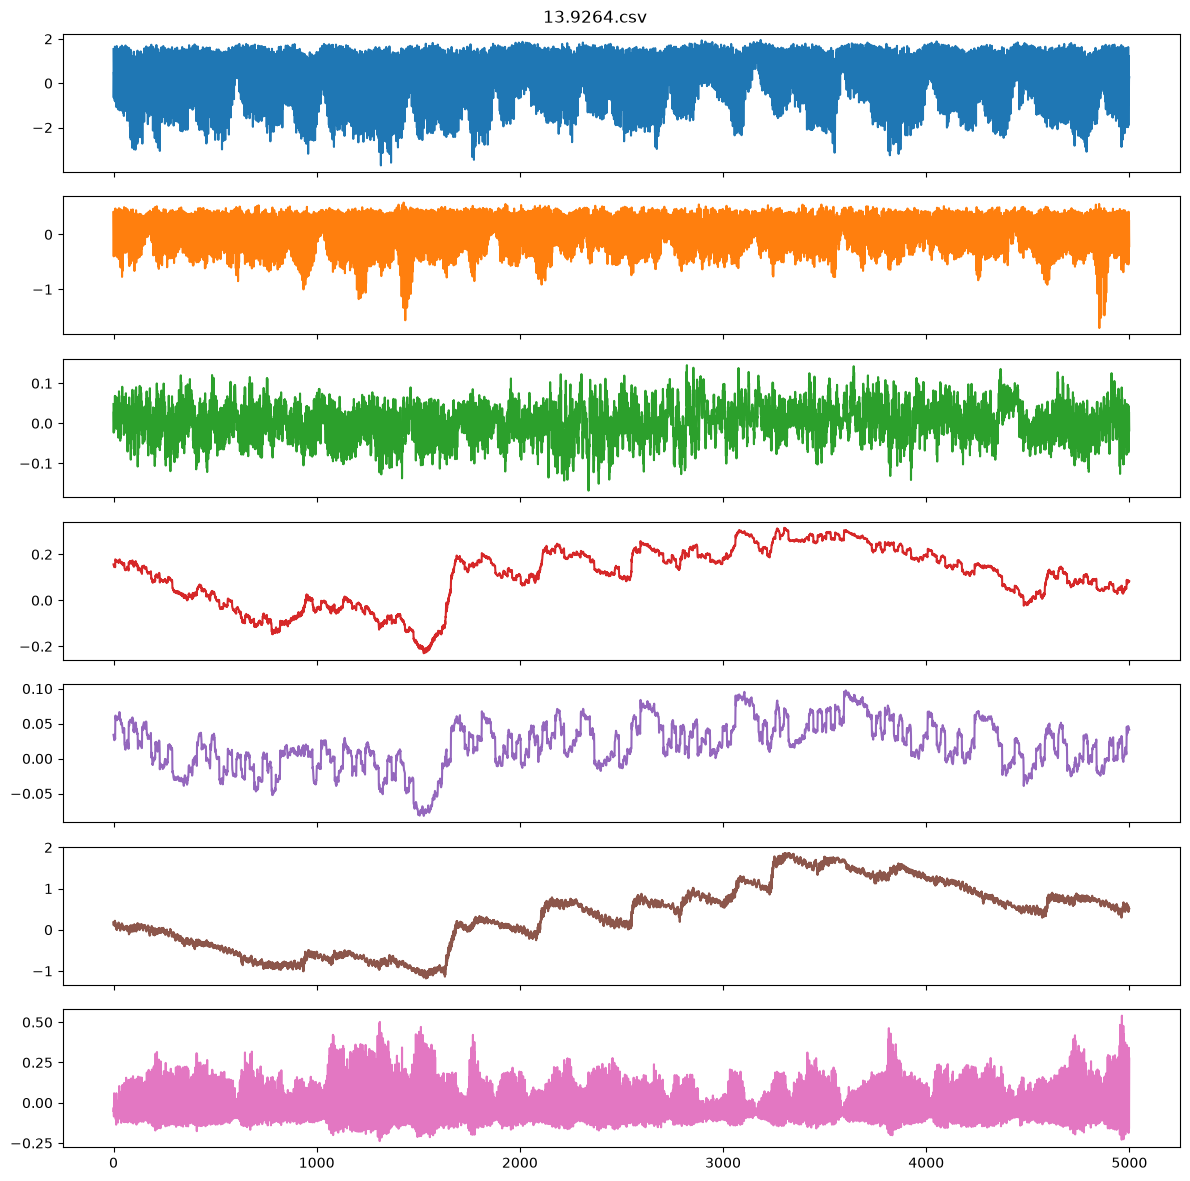

In [2]:
sensor_names = [
    'tachometer',
    'underhang_axial', 'underhang_radial', 'underhang_tangential',
    'overhang_axial', 'overhang_radial', 'overhang_tangential',
    'microphone',
]

sample_file = files[0]
sample = pd.read_csv(sample_file, header=None, nrows=5_000)
sample.columns = sensor_names if sample.shape[1] == 8 else [f'sensor_{i}' for i in range(sample.shape[1])]

print(f'Sample file: {sample_file.name}')
print(f'Shape of first 5,000 rows: {sample.shape}')
display(sample.head())
display(sample.describe().T[['count', 'mean', 'std', 'min', 'max']])
display(sample.isna().sum().rename('missing').to_frame())

sample.iloc[:, 1:].plot(subplots=True, figsize=(12, 12), legend=False, title=sample_file.name)
plt.tight_layout()
plt.show()